In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

In [2]:
X, y = make_regression(n_samples=500, n_features=5, noise=20, random_state=42)

In [3]:
X

array([[ 0.56091945, -0.37001103, -0.29548032, -0.25879606,  1.59864717],
       [-1.02438764, -0.92693047, -0.25256815, -0.05952536, -3.24126734],
       [-2.65096981,  0.10643023,  1.09150685, -0.25497722,  1.50399299],
       ...,
       [ 0.05820872,  0.38531738, -1.1429703 , -0.88385744,  0.15372511],
       [ 0.03200415,  0.29929258, -0.75341787,  1.30174129,  1.5615112 ],
       [-1.363174  , -1.59812435,  0.18970617,  0.46217267,  2.02430962]])

In [4]:
y

array([ -47.41232717, -132.48017391,  -59.38522519, -113.00164269,
       -174.77245461,  -16.25926228,   35.95148354, -225.75086965,
         45.01619425,  138.38540153,  -71.94464523, -108.61031706,
       -113.04593184,   49.29681645,   76.90035267,   15.8953671 ,
        208.78606404,   50.45278798,   59.30432199,   79.09632064,
         61.94268591,   73.64930947, -174.29007455,  309.76132926,
       -108.58408404,   69.20141543,   50.79695235,   11.67025323,
       -114.1495907 ,  -96.37889023,   94.56987014,  115.1902188 ,
       -126.19193218,  -22.11105791,   64.13759503,   98.82144202,
       -205.47978924,   -0.90847623,   36.82289112,  231.96858085,
         29.52314258, -221.24008801,   74.65061561,   -4.35493074,
        117.7331851 ,   49.4788483 ,   17.01660282,   52.20811627,
       -113.99290686,  -21.97176361,  -29.59372149, -396.17604931,
        109.97856708, -246.81545748,  134.51622047,   98.79778984,
         43.30329333,  -77.91209614,   -5.73371946, -178.15214

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Одиночное дерево решений

In [6]:
single_tree = DecisionTreeRegressor(random_state=42)
single_tree.fit(X_train, y_train)
y_pred_tree = single_tree.predict(X_test)
mse_tree = mean_squared_error(y_test, y_pred_tree)

Случайный лес

In [7]:
random_forest = RandomForestRegressor(n_estimators=100, random_state=42)
random_forest.fit(X_train, y_train)
y_pred_forest = random_forest.predict(X_test)
mse_forest = mean_squared_error(y_test, y_pred_forest)

In [8]:
print(f"Среднеквадратичная ошибка (Decision Tree): {mse_tree:.2f}")
print(f"Среднеквадратичная ошибка (Random Forest): {mse_forest:.2f}")

Среднеквадратичная ошибка (Decision Tree): 4038.97
Среднеквадратичная ошибка (Random Forest): 1292.93


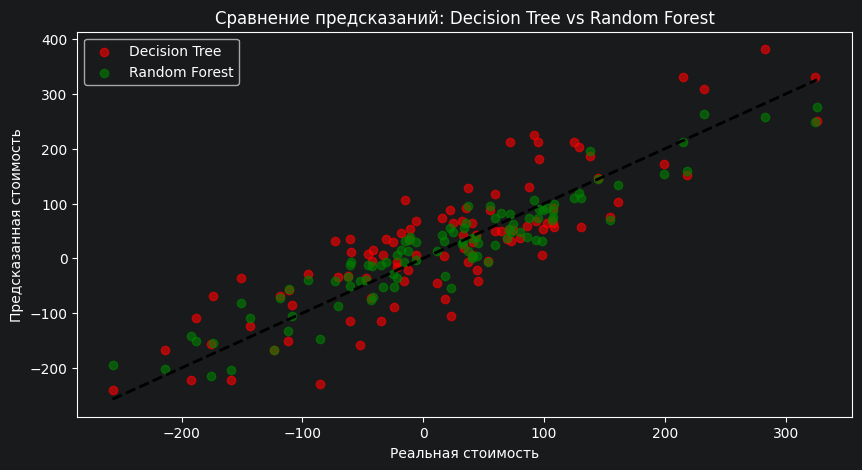

In [9]:
plt.figure(figsize=(10, 5))
plt.scatter(y_test, y_pred_tree, color='red', label='Decision Tree', alpha=0.6)
plt.scatter(y_test, y_pred_forest, color='green', label='Random Forest', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel('Реальная стоимость')
plt.ylabel('Предсказанная стоимость')
plt.title('Сравнение предсказаний: Decision Tree vs Random Forest')
plt.legend()
plt.show()